# Projet classification sur PathMNIST

1. **Early stopping** : chaque entraînement garde le checkpoint de l'époque où la perte de validation est minimale. On s'arrête quand la perte de validation ne s'améliore plus depuis `PATIENCE` époques, avec un budget de `MAX_EPOCHS`.
2. **Normalisation de coloration de Macenko** : la référence est estimée uniquement sur le jeu d'entraînement, puis la même transformation est appliquée aux 9 000 images d'entraînement, à la validation et aux deux jeux de test.
3. **Ticket gagnant** : élagage itératif des poids, avec réinitialisation à l'initialisation d'origine et contrôle par réinitialisation aléatoire.

Les cellules de préparation des données et de normalisation utilisent la même référence Macenko pour tous les splits, sans ajustement sur la validation ni sur les tests.

In [46]:
import os
for f in ["trajectoires_v6.pt", "controles_v6.pt", "references_v6.pt"]:
    if os.path.exists(f): os.remove(f)

# 1. Création du CNN

In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import pandas as pd
import matplotlib.pyplot as plt
!pip install medmnist
from medmnist import PathMNIST,INFO
!pip install torchstain
import torchstain

In [3]:

class CNN(nn.Module):
    def __init__(self, in_channels, num_classes):
        super(CNN, self).__init__()

        # Bloc 1 : 28x28 -> 14x14
        self.conv1a = nn.Conv2d(in_channels, 32, kernel_size=3, padding=1, stride=1)
        self.bn1a = nn.BatchNorm2d(32)

        self.conv1b = nn.Conv2d(32, 32, kernel_size=3, padding=1, stride=1)
        self.bn1b = nn.BatchNorm2d(32)

        # Bloc 2 : 14x14 -> 7x7
        self.conv2a = nn.Conv2d(32, 64, kernel_size=3, padding=1, stride=1)
        self.bn2a = nn.BatchNorm2d(64)

        self.conv2b = nn.Conv2d(64, 64, kernel_size=3, padding=1, stride=1)
        self.bn2b = nn.BatchNorm2d(64)

        # Bloc 3 : 7x7 -> 3x3
        self.conv3a = nn.Conv2d(64, 128, kernel_size=3, padding=1, stride=1)
        self.bn3a = nn.BatchNorm2d(128)

        self.conv3b = nn.Conv2d(128, 128, kernel_size=3, padding=1, stride=1)
        self.bn3b = nn.BatchNorm2d(128)

        # Max-pooling
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Couches denses
        self.fc1 = nn.Linear(128 * 3 * 3, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = F.relu(self.conv1a(x)) #self.bn1a(
        x = F.relu(self.conv1b(x))
        x = self.pool(x)

        x = F.relu(self.conv2a(x))
        x = F.relu(self.conv2b(x))
        x = self.pool(x)

        x = F.relu(self.conv3a(x))
        x = F.relu(self.conv3b(x))
        x = self.pool(x)

        x = x.reshape(x.shape[0], -1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [5]:
seed_rng = 42
num_classes = 9

### Chargement des données

In [6]:
def load(split):
    ds = PathMNIST(split=split,download=True,size=28)
    return ds.imgs, ds.labels.reshape(-1)

x_train_full, y_train_full = load("train")
x_val,y_val = load("val")
x_test, y_test = load("test")

### Sous-ensemble de 9 000 images d'entraînement

In [7]:
rng = np.random.default_rng(seed_rng)
idx_9k = np.stack([rng.choice(np.where(y_train_full == c)[0], 1000, replace=False)
                   for c in range(9)])           # (9, 1000) : 1000 images par classe
idx_4k5 = idx_9k[:, :500].ravel()                # 500 premières de chaque classe
idx = idx_9k.ravel()

x_train_2x, y_train_2x = x_train_full[idx_4k5], y_train_full[idx_4k5]    # socle : 4 500
x_train, y_train = x_train_full[idx], y_train_full[idx]      # 9 000 vraies images

x_train_dup = np.concatenate([x_train_2x, x_train_2x])     # 4 500 + les mêmes 4 500
y_train_dup = np.concatenate([y_train_2x, y_train_2x])

### Validation officielle -> 2 000 test du même centre et 8 000 validation restantes

In [8]:
perm = np.random.default_rng(seed_rng + 1).permutation(len(y_val))
x_test_same, y_test_same = x_val[perm[:2000]], y_val[perm[:2000]]
x_val, y_val = x_val[perm[2000:]], y_val[perm[2000:]]

In [9]:
print(x_train.shape)

(9000, 28, 28, 3)


Format des données en N, hauteur, largeur, canaux or nn.Conv2d attend N, canaux, hauteur, largeur

## Analyse préliminaire

In [10]:
splits = {
    "train officiel": (x_train_full, y_train_full),
    "train 9 000": (x_train, y_train),
    "validation 8 000": (x_val, y_val),
    "test même centre": (x_test_same, y_test_same),
    "test autre centre": (x_test, y_test),
}
names = [INFO["pathmnist"]["label"][str(i)] for i in range (9)]

### Taille et répartition des classes

In [11]:
# 1. Taille et répartition des classes (en %)
table = pd.DataFrame({k: np.bincount(y, minlength=9) / len(y) * 100 for k, (_, y) in splits.items()},
                     index=names).round(1)
table.loc["effectif"] = [len(y) for _, y in splits.values()]
print(table)

                                      train officiel  train 9 000  \
adipose                                         10.4         11.1   
background                                      10.6         11.1   
debris                                          11.5         11.1   
lymphocytes                                     11.6         11.1   
mucus                                            8.9         11.1   
smooth muscle                                   13.5         11.1   
normal colon mucosa                              8.8         11.1   
cancer-associated stroma                        10.4         11.1   
colorectal adenocarcinoma epithelium            14.3         11.1   
effectif                                     89996.0       9000.0   

                                      validation 8 000  test même centre  \
adipose                                           10.5              10.2   
background                                        10.7              10.2   
debris      

### Exemples d'images par classe

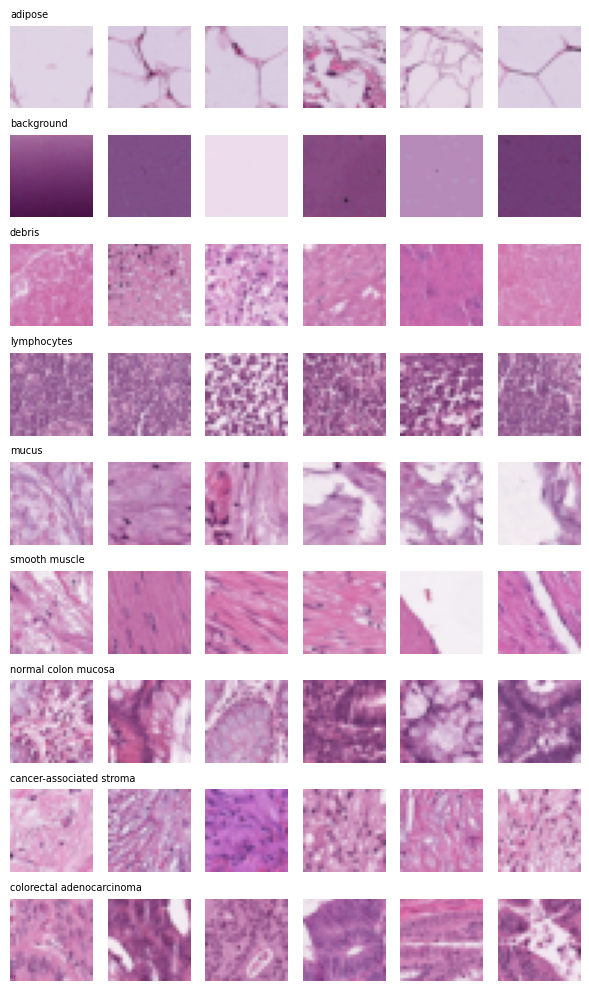

In [12]:
# 2. Exemples : 6 images par classe
fig, ax = plt.subplots(9, 6, figsize=(6, 10))
for c in range(9):
    imgs = x_train_full[idx][y_train_full[idx] == c][:6]
    for j in range(6):
        ax[c, j].imshow(imgs[j]); ax[c, j].axis("off")
    ax[c, 0].set_title(names[c][:25], fontsize=7, loc="left")
plt.tight_layout()
plt.show()

### Différences entre les centres

       train officiel  train 9 000  validation 8 000  test même centre  \
moy R           188.8        189.3             189.0             189.5   
moy G           135.9        137.6             136.2             136.8   
moy B           180.0        180.8             180.3             180.3   
std R            31.5         31.7              31.4              31.4   
std G            45.1         45.5              45.1              45.4   
std B            31.7         32.1              31.7              31.8   

       test autre centre  
moy R              185.3  
moy G              136.5  
moy B              180.9  
std R               37.5  
std G               53.5  
std B               38.6  


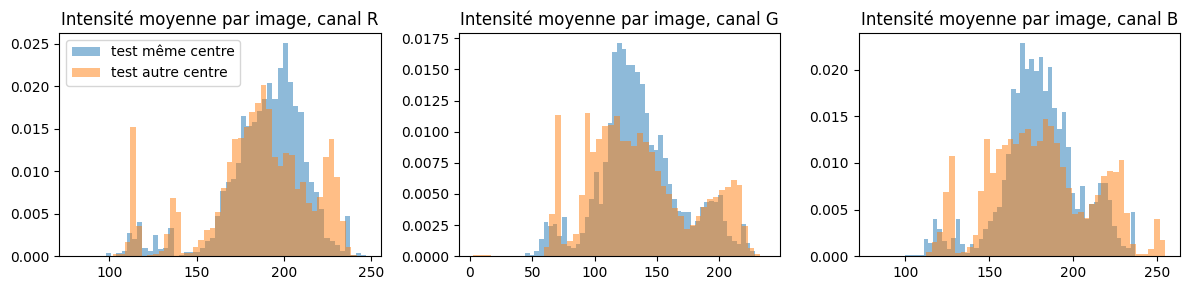

In [13]:
# 3. Décalage entre centres : couleur moyenne par canal
stats = pd.DataFrame({k: np.r_[x.reshape(-1, 3).mean(0), x.reshape(-1, 3).std(0)]
                      for k, (x, _) in splits.items()},
                     index=["moy R", "moy G", "moy B", "std R", "std G", "std B"]).round(1)
print(stats)

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for i, canal in enumerate("RGB"):
    for k in ["test même centre", "test autre centre"]:
        x = splits[k][0]
        ax[i].hist(x[..., i].reshape(len(x), -1).mean(1), bins=50, alpha=0.5, density=True, label=k)
    ax[i].set_title(f"Intensité moyenne par image, canal {canal}")
ax[0].legend()
plt.tight_layout()
plt.show()

## Données pour l'entraînement

### Centrage et réduction par canal

La référence Macenko est estimée uniquement à partir du jeu d'entraînement. Elle sert à normaliser la branche Macenko (train, validation et tests). La baseline reste strictement inchangée et utilise les images originales.

In [14]:
mean = x_train.reshape(-1, 3).mean(0) / 255.0
std = x_train.reshape(-1, 3).std(0) / 255.0

### Normalisation de coloration par la méthode de Macenko

Macenko constitue ici la **configuration avec traitement**, comparée à une baseline conservée sans augmentation ni normalisation.

- La matrice de coloration cible et les concentrations de référence sont estimées **uniquement à partir d'un échantillon du jeu d'entraînement**.
- Cette référence est appliquée aux **9 000 images d'entraînement** de la configuration Macenko, ainsi qu'à la validation et aux deux jeux de test.
- La référence n'est jamais recalculée à partir de la validation ou des tests : cela évite toute fuite d'information.
- La baseline `sans aug.` conserve les images originales pour l'entraînement, la validation et les tests.
- La configuration `aug.` correspond aux mêmes 9 000 images, après normalisation Macenko. Il ne s'agit pas de créer des copies supplémentaires : chaque image est normalisée une seule fois.

In [15]:
# --- Normalisation de coloration de Macenko ---
# Estimation de la référence sur un échantillon du train uniquement.
MACENKO_BETA = 0.15
MACENKO_ALPHA = 1.0
MACENKO_N_REF = min(500, len(x_train))
MACENKO_SEED = 2026

def _rgb_to_od(img):
    """RGB uint8 -> densité optique (OD)."""
    return -np.log((img.astype(np.float64) + 1.0) / 255.0)

def _estimate_stain_matrix(od_pixels, beta=MACENKO_BETA, alpha=MACENKO_ALPHA):
    """Estime les deux vecteurs de coloration de Macenko à partir de pixels OD."""
    od_pixels = od_pixels[np.linalg.norm(od_pixels, axis=1) > beta]
    if len(od_pixels) < 3:
        raise ValueError("Pas assez de pixels au-dessus du seuil OD pour estimer les colorations.")
    _, eigvecs = np.linalg.eigh(np.cov(od_pixels, rowvar=False))
    plane = eigvecs[:, -2:]
    projected = od_pixels @ plane
    angles = np.arctan2(projected[:, 1], projected[:, 0])
    phi = np.percentile(angles, [alpha, 100.0 - alpha])
    stains = np.stack([
        plane @ np.array([np.cos(phi[0]), np.sin(phi[0])]),
        plane @ np.array([np.cos(phi[1]), np.sin(phi[1])])
    ], axis=1)
    stains /= np.linalg.norm(stains, axis=0, keepdims=True).clip(min=1e-12)
    # Ordre reproductible des deux colorations.
    if stains[0, 0] < stains[0, 1]:
        stains = stains[:, ::-1]
    return stains

def _estimate_concentrations(od, stain_matrix):
    """Résout OD = concentrations x matrice des colorations."""
    return np.linalg.lstsq(stain_matrix, od.reshape(-1, 3).T, rcond=None)[0]

def fit_macenko_reference(x_reference):
    """Construit la référence Macenko à partir d'images du seul jeu train."""
    rng = np.random.default_rng(MACENKO_SEED)
    chosen = rng.choice(len(x_reference), MACENKO_N_REF, replace=False)
    od_all = np.concatenate([_rgb_to_od(x_reference[i]).reshape(-1, 3) for i in chosen], axis=0)
    od_tissue = od_all[np.linalg.norm(od_all, axis=1) > MACENKO_BETA]
    target_stains = _estimate_stain_matrix(od_tissue)
    target_concentrations = _estimate_concentrations(od_tissue.reshape(1, -1, 3), target_stains)
    target_max = np.percentile(target_concentrations, 99, axis=1).clip(min=1e-6)
    return target_stains, target_max

def macenko_normalize_image(img, target_stains, target_max):
    """Normalise une image RGB vers la référence Macenko."""
    od = _rgb_to_od(img)
    flat = od.reshape(-1, 3)
    tissue = np.linalg.norm(flat, axis=1) > MACENKO_BETA
    if tissue.sum() < 3:
        return img.copy()
    try:
        source_stains = _estimate_stain_matrix(flat[tissue])
        concentrations = np.linalg.lstsq(source_stains, flat.T, rcond=None)[0]
        source_max = np.percentile(concentrations[:, tissue], 99, axis=1).clip(min=1e-6)
        concentrations *= (target_max / source_max)[:, None]
        reconstructed_od = (target_stains @ concentrations).T.reshape(img.shape)
        normalized = 255.0 * np.exp(-reconstructed_od) - 1.0
        return np.clip(normalized, 0, 255).astype(np.uint8)
    except (ValueError, np.linalg.LinAlgError):
        # En cas d'estimation instable sur une image, on conserve l'image initiale.
        return img.copy()

def macenko_normalize_dataset(x, target_stains, target_max, label):
    out = np.empty_like(x, dtype=np.uint8)
    for i, img in enumerate(x):
        out[i] = macenko_normalize_image(img, target_stains, target_max)
        if (i + 1) % 2000 == 0 or i + 1 == len(x):
            print(f"{label} : {i + 1}/{len(x)} images normalisées")
    return out

# La référence est ajustée uniquement sur les 9 000 images du train.
macenko_stains, macenko_target_max = fit_macenko_reference(x_train)

# Deux branches indépendantes :
# 1) baseline : images originales, sans augmentation ni Macenko ;
# 2) configuration Macenko : train, validation et tests normalisés avec la même référence.
x_train_macenko = macenko_normalize_dataset(x_train, macenko_stains, macenko_target_max, "Train")
x_val_macenko = macenko_normalize_dataset(x_val, macenko_stains, macenko_target_max, "Validation")
x_test_same_macenko = macenko_normalize_dataset(
    x_test_same, macenko_stains, macenko_target_max, "Test même centre"
)
x_test_macenko = macenko_normalize_dataset(x_test, macenko_stains, macenko_target_max, "Test autre centre")

def make_dataset(x, y):
    x = torch.tensor(x, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
    # Standardisation par image et par canal, comme dans le reste du notebook.
    m = x.mean(dim=(2, 3), keepdim=True)
    std_img = x.std(dim=(2, 3), keepdim=True).clamp_min(1e-3)
    x = (x - m) / std_img
    return TensorDataset(x, torch.tensor(y, dtype=torch.long))

# Baseline inchangée : données brutes pour train, validation et tests.
train_set = make_dataset(x_train, y_train)
val_loader = DataLoader(make_dataset(x_val, y_val), batch_size=1024)
test_same_loader = DataLoader(make_dataset(x_test_same, y_test_same), batch_size=1024)
test_other_loader = DataLoader(make_dataset(x_test, y_test), batch_size=1024)

# Branche Macenko : même référence estimée sur le train, appliquée à tous les splits.
train_set_aug = make_dataset(x_train_macenko, y_train)
val_loader_macenko = DataLoader(make_dataset(x_val_macenko, y_val), batch_size=1024)
test_same_loader_macenko = DataLoader(make_dataset(x_test_same_macenko, y_test_same), batch_size=1024)
test_other_loader_macenko = DataLoader(make_dataset(x_test_macenko, y_test), batch_size=1024)

print("Baseline : images originales.")
print("Configuration Macenko : normalisation du train, de la validation et des tests avec la référence du train.")

Train : 2000/9000 images normalisées
Train : 4000/9000 images normalisées
Train : 6000/9000 images normalisées
Train : 8000/9000 images normalisées
Train : 9000/9000 images normalisées
Validation : 2000/8004 images normalisées
Validation : 4000/8004 images normalisées
Validation : 6000/8004 images normalisées
Validation : 8000/8004 images normalisées
Validation : 8004/8004 images normalisées
Test même centre : 2000/2000 images normalisées
Test autre centre : 2000/7180 images normalisées
Test autre centre : 4000/7180 images normalisées
Test autre centre : 6000/7180 images normalisées
Test autre centre : 7180/7180 images normalisées
Baseline : images originales.
Configuration Macenko : normalisation du train, de la validation et des tests avec la référence du train.


In [16]:
# Deux configurations sont conservées :
# - train_set : baseline sur les images originales ;
# - train_set_aug : 9 000 images normalisées par Macenko.

## Evaluation

In [17]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += criterion(out, y).item() * len(y)
        correct += (out.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n

### Outils d'évaluation complémentaires

- `predict(model, loader)` renvoie les vraies classes, les classes prédites et les probabilités.
- `scores(model, train_acc)` calcule, sur la validation et sur les deux tests :
  - l'exactitude, le F1 macro et le rappel de la classe tumorale (`TUM_CLASS = 8`) ;
  - le F1 de chaque classe et la matrice de confusion ;
  - les deux écarts : surapprentissage = `train_acc − acc_same`, centre = `acc_same − acc_other`.

Les tests ne sont évalués qu'en partie 4.

In [18]:
from sklearn.metrics import f1_score, recall_score, confusion_matrix
import copy, time

TUM_CLASS = 8    # "colorectal adenocarcinoma epithelium" : la classe tumorale
print("classe tumorale :", names[TUM_CLASS])

@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, labels = [], []
    for x, y in loader:
        probs.append(F.softmax(model(x.to(device)), dim=1).cpu())
        labels.append(y)
    probs = np.nan_to_num(torch.cat(probs).numpy(), nan=1 / 9)
    return torch.cat(labels).numpy(), probs.argmax(1), probs

SPLITS_BASELINE = [("val", "validation", val_loader), ("same", "test même centre", test_same_loader),
                   ("other", "test autre centre", test_other_loader)]
SPLITS_MACENKO = [("val", "validation", val_loader_macenko),
                  ("same", "test même centre", test_same_loader_macenko),
                  ("other", "test autre centre", test_other_loader_macenko)]

def scores(model, train_acc, data_label="sans aug."):
    out = {}
    splits_to_use = SPLITS_BASELINE if data_label == "sans aug." else SPLITS_MACENKO
    for key, _, loader in splits_to_use:
        y, p, probs = predict(model, loader)
        out[f"acc_{key}"] = float((y == p).mean())
        out[f"f1_{key}"] = f1_score(y, p, average="macro", zero_division=0)
        out[f"rappel_tum_{key}"] = recall_score(y, p, labels=[TUM_CLASS], average="macro", zero_division=0)
        out[f"f1_classes_{key}"] = f1_score(y, p, labels=list(range(9)), average=None, zero_division=0)
        out[f"cm_{key}"] = confusion_matrix(y, p, labels=list(range(9)), normalize="true")
    out["ecart_surapprentissage"] = train_acc - out["acc_same"]
    out["ecart_centre"] = out["acc_same"] - out["acc_other"]
    return out

classe tumorale : colorectal adenocarcinoma epithelium


## Entraînement : Adam + early stopping

Une **seule** fonction, `train_model`, sert à tous les entraînements du notebook.

- **Early stopping.** À chaque époque, on calcule la perte de validation. Si elle est la plus basse vue jusque-là, on copie les poids (le **meilleur checkpoint**). On arrête quand elle ne s'est pas améliorée depuis `PATIENCE` époques, ou au bout de `MAX_EPOCHS`. À la fin, on **recharge le meilleur checkpoint** : c'est lui qui est évalué et, pour le ticket, c'est lui qui est élagué.
- **Ce que la fonction renvoie** : `best_epoch`, l'époque du meilleur checkpoint (l'« époque d'arrêt » de Frankle & Carbin), et `epochs_run`, le nombre d'époques réellement faites.
- **Le cosinus** est réglé sur `MAX_EPOCHS`. Il suit donc le même calendrier dans tous les entraînements, quel que soit le moment de l'arrêt.
- **Les paramètres** :
  - `data` : `train_set` (baseline originale) ou `train_set_aug` (9 000 images normalisées par Macenko) ;
  - `init_state` : θ0 (ticket) ou une autre initialisation (contrôle) ;
  - `masks` : le masque d'élagage, réappliqué après chaque `optimizer.step()`, car les moments d'Adam feraient revivre les poids élagués.
- **`train_acc`** est mesurée sur le jeu utilisé pour l'entraînement : images originales pour la baseline, images Macenko pour la configuration `aug.`.

**Taux d'apprentissage.** `LEARNING_RATE = 0.005` (valeur demandée). Si des entraînements divergent ou si les courbes de validation sont très bruitées, mettre `1e-3` (valeur standard d'Adam). C'est la seule ligne à changer.

In [19]:
LEARNING_RATE = 0.0003   # Adam ; mettre 1e-3 pour un entraînement plus stable
batch_size = 128
MAX_EPOCHS = 100        # même budget d'époques pour tous les entraînements
PATIENCE = 15           # arrêt après 15 époques sans amélioration de la perte de validation
SEEDS = [0, 1, 2]
DIVERGENCE_ACC = 0.20

In [47]:
def prunable(model):
    # Poids élagables : les poids (pas les biais) des 6 conv et des 2 couches denses
    return {name: p for name, p in model.named_parameters() if name.endswith("weight")}

@torch.no_grad()
def apply_masks(model, masks):
    for name, p in prunable(model).items():
        p.mul_(masks[name])

def to_cpu(d):
    return {k: v.detach().cpu().clone() for k, v in d.items()}

def model_from_state(state):
    model = CNN(in_channels=3, num_classes=num_classes).to(device)
    model.load_state_dict(state)
    return model

train_eval_loader = DataLoader(train_set, batch_size=1024)   # 9 000 images d'entraînement normalisées

def train_model(seed, data=None, init_state=None, masks=None, lr=None,
                max_epochs=None, patience=None, verbose=False, validation_loader=None):
    data = train_set if data is None else data
    validation_loader = val_loader if validation_loader is None else validation_loader
    train_eval_loader = DataLoader(data, batch_size=1024)
    lr = LEARNING_RATE if lr is None else lr
    max_epochs = MAX_EPOCHS if max_epochs is None else max_epochs
    patience = PATIENCE if patience is None else patience

    torch.manual_seed(seed)
    np.random.seed(seed)
    model = CNN(in_channels=3, num_classes=num_classes).to(device)
    if init_state is not None:
        model.load_state_dict(init_state)          # θ0 (ticket) ou autre init (contrôle)
    if masks is not None:
        apply_masks(model, masks)                  # m ⊙ θ0
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    # optimizer = torch.optim.AdamW(
    # model.parameters(),
    # lr=lr,
    # weight_decay=0.0001)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max_epochs)
    #scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    # optimizer,
    # mode='min',
    # factor=0.5,
    # patience=3,
    # min_lr=1e-6
    # )

    g = torch.Generator().manual_seed(seed)        # même ordre des batchs pour une graine donnée
    train_loader = DataLoader(data, batch_size=batch_size, shuffle=True, generator=g)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0
    diverged, epoch = False, 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = criterion(model(x), y)
            if not torch.isfinite(loss):
                diverged = True
                break
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            if masks is not None:
                apply_masks(model, masks)          # les poids élagués restent à 0
        if diverged:
            break
        scheduler.step()

        tr_loss, tr_acc = evaluate(model, train_eval_loader, criterion)
        va_loss, va_acc = evaluate(model, validation_loader, criterion)
        #scheduler.step(va_loss)

        for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[k].append(v)
        if verbose and epoch % 10 == 0:
            print(f"graine {seed} | époque {epoch:3d} | train {tr_loss:.3f} / {tr_acc:.3f} "
                  f"| val {va_loss:.3f} / {va_acc:.3f}")

        if va_loss < best_loss:                    # meilleur checkpoint
            best_loss, best_epoch, wait = va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)          # on évalue (et on élague) le meilleur checkpoint
    _, tr_acc = evaluate(model, train_eval_loader, criterion)
    va_loss, va_acc = evaluate(model, validation_loader, criterion)
    return model, history, {"train_acc": tr_acc, "val_acc": va_acc, "val_loss": va_loss,
                            "best_epoch": best_epoch, "epochs_run": len(history["val_loss"]),
                            "diverged": diverged or best_state is None or tr_acc < DIVERGENCE_ACC}

# 2. Configuration avec normalisation de coloration par Macenko

La baseline `sans aug.` reste inchangée : elle utilise les images originales, sans Macenko.

La configuration `aug.` utilise les **9 000 images d'entraînement normalisées par Macenko**. La même référence, estimée uniquement sur le train, est appliquée à la validation et aux deux jeux de test lorsque le modèle de cette configuration est évalué.

Cette comparaison mesure donc l'effet de la normalisation de coloration de Macenko par rapport à la baseline originale.

In [48]:
# Configuration Macenko : les 9 000 images d'origine, normalisées une seule fois.
# La baseline train_set (images brutes) n'est pas modifiée.
print("Méthode : normalisation de coloration de Macenko")
print(pd.DataFrame({"train original (baseline)": np.bincount(y_train, minlength=num_classes),
                    "train après Macenko": np.bincount(y_train, minlength=num_classes)},
                   index=names))
print("total :", len(train_set_aug), "images dans chaque configuration (9 000 attendues)")

Méthode : normalisation de coloration de Macenko
                                      train original (baseline)  \
adipose                                                    1000   
background                                                 1000   
debris                                                     1000   
lymphocytes                                                1000   
mucus                                                      1000   
smooth muscle                                              1000   
normal colon mucosa                                        1000   
cancer-associated stroma                                   1000   
colorectal adenocarcinoma epithelium                       1000   

                                      train après Macenko  
adipose                                              1000  
background                                           1000  
debris                                               1000  
lymphocytes                             

### Vérification visuelle : images d'origine et images normalisées par Macenko

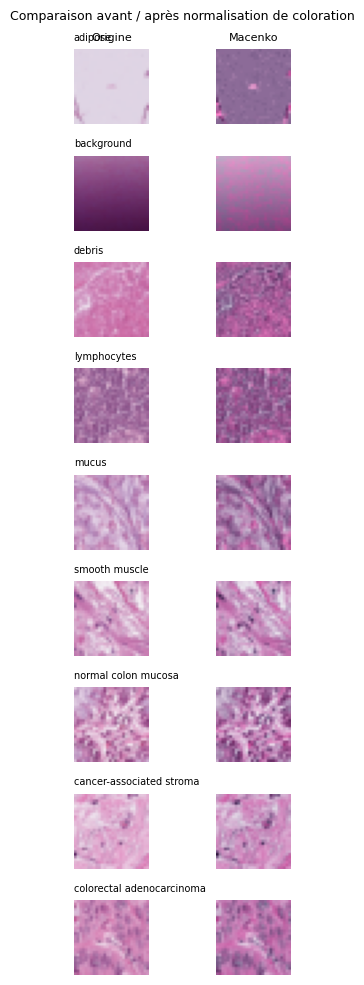

       train original  train Macenko
moy R           189.3          180.6
moy G           137.6          125.4
moy B           180.8          174.0
std R            31.7           27.4
std G            45.5           36.9
std B            32.1           26.0


In [49]:
rng_vis = np.random.default_rng(0)
fig, ax = plt.subplots(9, 2, figsize=(3.5, 10))
for c in range(num_classes):
    idx_c = np.where(y_train == c)[0]
    i = idx_c[0]
    ax[c, 0].imshow(x_train[i])
    ax[c, 1].imshow(x_train_macenko[i])
    for a in ax[c]:
        a.axis("off")
    ax[c, 0].set_title(names[c][:25], fontsize=7, loc="left")
    if c == 0:
        ax[c, 0].set_title("Origine", fontsize=8)
        ax[c, 1].set_title("Macenko", fontsize=8)
plt.suptitle("Comparaison avant / après normalisation de coloration", fontsize=9)
plt.tight_layout(); plt.show()

print(pd.DataFrame({k: np.r_[x.reshape(-1, 3).mean(0), x.reshape(-1, 3).std(0)]
                    for k, x in [("train original", x_train), ("train Macenko", x_train_macenko)]},
                   index=["moy R", "moy G", "moy B", "std R", "std G", "std B"]).round(1))

# 3. Ticket gagnant (Frankle & Carbin, 2019) avec early stopping

**Un tour** (élagage itératif, « stratégie 1 » de l'annexe B) :

1. On entraîne `m ⊙ θ0` avec early stopping (même `MAX_EPOCHS` et même `PATIENCE` à chaque tour).
2. On élague par magnitude, couche par couche, les poids **du meilleur checkpoint** (époque de perte de validation minimale). Cela donne un nouveau masque `m`.
3. On remet les poids survivants à leur valeur dans **θ0**, l'initialisation d'origine.

C'est le protocole du papier : Frankle & Carbin élaguent le réseau à l'itération d'arrêt précoce et rapportent cette itération comme mesure de vitesse d'apprentissage.

**Fixé** (Conv-6 du papier) : élagage non structuré, couche par couche. À chaque tour, on retire 15 % des poids restants dans les conv, 20 % dans `fc1` et 10 % dans `fc2`.

**Deux trajectoires par graine**, qui diffèrent par le prétraitement des données :

- `sans aug.` : baseline sur les images originales ; le tour 0 est le **socle**, les tours suivants donnent **+ ticket** ;
- `aug.` : normalisation Macenko des 9 000 images d'entraînement, et de la validation et des tests avec la même référence ; le tour 0 est **+ Macenko**, les tours suivants donnent **Macenko + ticket**.

Les 3 graines vont toutes jusqu'à `N_ROUNDS` tours. On peut ainsi donner, pour chaque niveau d'élagage, une moyenne ± écart-type de l'exactitude et de l'époque d'arrêt. Coût : 2 × 3 × (`N_ROUNDS` + 1) entraînements, plus 6 contrôles. Avec l'early stopping, chaque entraînement s'arrête en général bien avant 100 époques.

## 3.1 Réglages

In [50]:
PRUNE_RATE = {"conv": 0.15, "fc1": 0.20, "fc2": 0.10}   # par tour, fraction des poids encore vivants
N_ROUNDS = 14                 # tours 0..10 : Pm de 100 % à environ 17 %
GRID_ROUNDS = [2, 4, 5,6,7, 8, 10,12,13,14] # valeurs candidates pour n* (choix sur la validation)
SEED_TUNE = 0                 # graine de réglage de n* (protocole G4)
REINIT_OFFSET = 1000          # init du contrôle = graine + 1000
TOL_SELECTION = 0.005         # 0,5 point d'exactitude de validation
DATASETS = {"sans aug.": train_set, "aug.": train_set_aug}

## 3.2 Fonctions d'élagage et trajectoire

- `prune_step(model, masks)` réalise un tour d'élagage. Dans chaque couche, on retire les `k = taux × vivants` poids vivants de plus petite valeur absolue. Les poids déjà morts ne peuvent pas être choisis de nouveau.
- `sparsity(masks)` donne Pm (la fraction de poids élagables gardés) et le pourcentage gardé par couche.
- `initial_state(seed)` renvoie θ0, exactement l'initialisation de `train_model(seed)`.
- `lottery_trajectory(seed, data, n_rounds)` enchaîne les tours. Le modèle renvoyé par `train_model` est déjà le meilleur checkpoint, et c'est lui qui est élagué. Si un tour diverge, on élague le dernier modèle sain.

## 3.3 Trajectoires : baseline originale vs Macenko, 3 graines

Chaque trajectoire compare la baseline sur images originales (`sans aug.`) à la configuration Macenko (`aug.`). Les deux configurations ont chacune leur validation correspondante.

**Important :** les anciens fichiers `trajectoires_v6.pt` et `controles_v6.pt`, calculés avec les deux branches normalisées, ne sont pas compatibles avec ce protocole. Les supprimer avant de relancer les entraînements.

In [51]:
def prunable(model):
    # Poids élagables : uniquement les poids des conv et fc (on exclut le batch norm 'bn')
    return {name: p for name, p in model.named_parameters() if name.endswith("weight") and "bn" not in name}

def layer_rate(name):
    if name.startswith("conv"):
        return PRUNE_RATE["conv"]
    return PRUNE_RATE[name.split(".")[0]]          # "fc1" ou "fc2"

def full_masks(model):
    return {name: torch.ones_like(p) for name, p in prunable(model).items()}

@torch.no_grad()
def prune_step(model, masks):
    new_masks = {}
    for name, p in prunable(model).items():
        m = masks[name]
        alive = m.bool()
        if not torch.isfinite(p[alive]).all():
            raise ValueError(f"{name} : poids NaN/infinis")
        k = int(round(layer_rate(name) * int(alive.sum())))
        new_m = m.clone()
        if k > 0:
            s = p.abs().masked_fill(~alive, float("inf"))   # poids déjà morts : jamais re-choisis
            idx = torch.topk(s.flatten(), k, largest=False).indices
            new_m.view(-1)[idx] = 0
        new_masks[name] = new_m
    return new_masks

def sparsity(masks):
    kept = sum(int(m.sum()) for m in masks.values())
    total = sum(m.numel() for m in masks.values())
    per_layer = {n: round(100 * float(m.mean()), 1) for n, m in masks.items()}
    return kept / total, kept, per_layer

def initial_state(seed):
    torch.manual_seed(seed)
    model = CNN(in_channels=3, num_classes=num_classes).to(device)
    return copy.deepcopy(model.state_dict())

def lottery_trajectory(seed, data, n_rounds, label="", validation_loader=None):
    theta0 = initial_state(seed)
    masks = full_masks(model_from_state(theta0))
    last_ok_model = model_from_state(theta0)
    rounds = []
    for r in range(n_rounds + 1):
        t0 = time.time()
        model, hist, res = train_model(seed, data=data, init_state=theta0, masks=masks, validation_loader=validation_loader)   # retour à θ0
        Pm, kept, per_layer = sparsity(masks)
        rounds.append({"round": r, "Pm": Pm, "n_poids": kept, "per_layer": per_layer, **res,
                       "history": hist, "state": to_cpu(model.state_dict()), "masks": to_cpu(masks)})
        print(f"{label:9s} graine {seed} | tour {r:2d} | Pm {100 * Pm:5.1f} % | train {res['train_acc']:.3f} "
              f"| val {res['val_acc']:.3f} | arrêt époque {res['best_epoch']:3d} ({res['epochs_run']} faites) "
              f"| {time.time() - t0:.0f} s" + ("  <-- DIVERGÉ" if res["diverged"] else ""))
        if not res["diverged"]:
            last_ok_model = model                  # meilleur checkpoint de ce tour
        if r < n_rounds:
            masks = prune_step(last_ok_model, masks)
    return rounds

In [52]:
import os
TRAJ_FILE = "trajectoires_v6.pt"
traj = torch.load(TRAJ_FILE, weights_only=False) if os.path.exists(TRAJ_FILE) else {}

for label, data in DATASETS.items():
    for s in SEEDS:
        if (label, s) in traj:
            print(f"{label} graine {s} : déjà calculée")
            continue
        traj[(label, s)] = lottery_trajectory(s, data, N_ROUNDS, label, val_loader if label == "sans aug." else val_loader_macenko)
        torch.save(traj, TRAJ_FILE)

sans aug. graine 0 | tour  0 | Pm 100.0 % | train 0.876 | val 0.758 | arrêt époque  34 (49 faites) | 70 s
sans aug. graine 0 | tour  1 | Pm  82.5 % | train 0.869 | val 0.775 | arrêt époque  40 (55 faites) | 77 s
sans aug. graine 0 | tour  2 | Pm  68.1 % | train 0.872 | val 0.783 | arrêt époque  40 (55 faites) | 77 s
sans aug. graine 0 | tour  3 | Pm  56.3 % | train 0.867 | val 0.789 | arrêt époque  34 (49 faites) | 69 s
sans aug. graine 0 | tour  4 | Pm  46.6 % | train 0.882 | val 0.799 | arrêt époque  40 (55 faites) | 76 s
sans aug. graine 0 | tour  5 | Pm  38.6 % | train 0.893 | val 0.809 | arrêt époque  48 (63 faites) | 88 s
sans aug. graine 0 | tour  6 | Pm  32.0 % | train 0.862 | val 0.809 | arrêt époque  29 (44 faites) | 61 s
sans aug. graine 0 | tour  7 | Pm  26.5 % | train 0.875 | val 0.816 | arrêt époque  51 (66 faites) | 92 s
sans aug. graine 0 | tour  8 | Pm  22.0 % | train 0.880 | val 0.822 | arrêt époque  51 (66 faites) | 91 s
sans aug. graine 0 | tour  9 | Pm  18.3 % | tr

## 3.4 Exactitude et époque d'arrêt pour chaque niveau d'élagage

Pour chaque niveau d'élagage (tour n, soit Pm), on donne la moyenne ± écart-type sur les 3 graines de quatre grandeurs :

- l'exactitude de validation du meilleur checkpoint ;
- l'exactitude d'entraînement ;
- l'écart entre les deux ;
- l'époque d'arrêt (`best_epoch`).

Selon Frankle & Carbin, un ticket gagnant atteint une **meilleure exactitude** avec une **époque d'arrêt plus précoce** que le réseau complet.


=== sans aug. : moyenne ± écart-type sur 3 graines ===
                 train_acc        val_acc écart train − val époque d'arrêt  divergences
tour Pm (%)                                                                            
0    100.0   0.888 ± 0.012  0.800 ± 0.038     0.088 ± 0.031    49.3 ± 14.6            0
1    82.5    0.887 ± 0.016  0.807 ± 0.030     0.079 ± 0.015     49.0 ± 8.2            0
2    68.1    0.883 ± 0.017  0.811 ± 0.027     0.073 ± 0.015     45.0 ± 5.6            0
3    56.3    0.888 ± 0.020  0.814 ± 0.025     0.074 ± 0.005    45.7 ± 10.1            0
4    46.6    0.896 ± 0.013  0.819 ± 0.018     0.078 ± 0.006    50.3 ± 10.0            0
5    38.6    0.901 ± 0.008  0.826 ± 0.016     0.075 ± 0.009     54.3 ± 5.5            0
6    32.0    0.890 ± 0.026  0.829 ± 0.019     0.062 ± 0.007    49.0 ± 17.3            0
7    26.5    0.891 ± 0.016  0.831 ± 0.014     0.061 ± 0.003     56.0 ± 4.4            0
8    22.0    0.885 ± 0.015  0.832 ± 0.011     0.054 ± 0.009    5

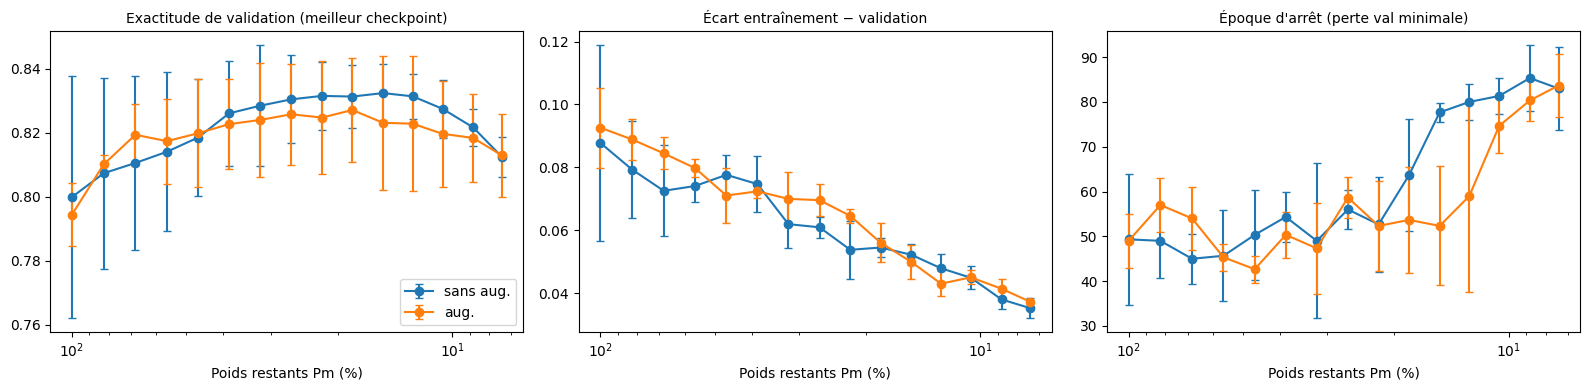

In [53]:
rows = [{"données": label, "graine": s, "tour": r["round"], "Pm (%)": round(100 * r["Pm"], 1),
         "train_acc": r["train_acc"], "val_acc": r["val_acc"], "écart train − val": r["train_acc"] - r["val_acc"],
         "époque d'arrêt": r["best_epoch"], "époques faites": r["epochs_run"], "divergé": r["diverged"]}
        for (label, s), t in traj.items() for r in t]
levels = pd.DataFrame(rows)
levels.to_csv("niveaux_elagage_v6.csv", index=False)

COLS_LVL = ["train_acc", "val_acc", "écart train − val", "époque d'arrêt"]
for label in DATASETS:
    d = levels[levels["données"] == label]
    t = d.groupby(["tour", "Pm (%)"])[COLS_LVL].agg(["mean", "std"])
    out = pd.DataFrame({c: [f"{m:.3f} ± {sd:.3f}" if c != "époque d'arrêt" else f"{m:.1f} ± {sd:.1f}"
                            for m, sd in zip(t[(c, "mean")], t[(c, "std")])] for c in COLS_LVL}, index=t.index)
    out["divergences"] = d.groupby(["tour", "Pm (%)"])["divergé"].sum().values
    print(f"\n=== {label} : moyenne ± écart-type sur {len(SEEDS)} graines ===")
    print(out.to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for label in DATASETS:
    d = levels[levels["données"] == label]
    for a, c in zip(ax, ["val_acc", "écart train − val", "époque d'arrêt"]):
        g = d.groupby("Pm (%)")[c]
        pm = np.array(sorted(g.groups, reverse=True))
        a.errorbar(pm, g.mean().reindex(pm), yerr=g.std().reindex(pm).fillna(0), fmt="o-", capsize=3, label=label)
for a, t in zip(ax, ["Exactitude de validation (meilleur checkpoint)", "Écart entraînement − validation",
                     "Époque d'arrêt (perte val minimale)"]):
    a.set_xscale("log"); a.invert_xaxis(); a.set_xlabel("Poids restants Pm (%)"); a.set_title(t, fontsize=10)
ax[0].legend(); plt.tight_layout(); plt.show()

## 3.5 Choix de Pm\* (validation, graine 0) et contrôle réinitialisé

**Règle de choix**, fixée avant de voir les résultats et appliquée séparément aux deux jeux de données. Sur la graine 0 et parmi `GRID_ROUNDS`, on prend la meilleure exactitude de validation. Si plusieurs valeurs sont à moins de 0,5 point de cette meilleure valeur, on prend la plus élaguée. Les tests ne sont pas regardés.

**Contrôle du papier.** On garde le même masque que le ticket au tour n\*, mais avec une **autre initialisation** (graine + 1000), les mêmes données et le même ordre des batchs. Si le ticket fait mieux que ce contrôle, c'est θ0 qui compte : c'est un vrai ticket gagnant.

In [54]:
n_star, controls = {}, {}
for label, data in DATASETS.items():
    t0 = traj[(label, SEED_TUNE)]
    cand = [r for r in t0 if r["round"] in GRID_ROUNDS and not r["diverged"]]
    if not cand:                                   # tout a divergé : on garde quand même la grille
        print(f"ATTENTION : {label}, tous les tours de la grille ont divergé (essayer LEARNING_RATE = 1e-3)")
        cand = [r for r in t0 if r["round"] in GRID_ROUNDS]
    best = max(r["val_acc"] for r in cand)
    n_star[label] = max(r["round"] for r in cand if r["val_acc"] >= best - TOL_SELECTION)
    print(f"{label} : n* = {n_star[label]} tours, Pm* = {100 * t0[n_star[label]]['Pm']:.1f} %")

    for s in SEEDS:
        masks_star = {k: v.to(device) for k, v in traj[(label, s)][n_star[label]]["masks"].items()}
        model, hist, res = train_model(s, data=data, init_state=initial_state(s + REINIT_OFFSET), masks=masks_star, validation_loader=val_loader if label == "sans aug." else val_loader_macenko)
        Pm, kept, _ = sparsity(masks_star)
        controls[(label, s)] = {"Pm": Pm, "n_poids": kept, **res, "history": hist, "state": to_cpu(model.state_dict())}
        print(f"   contrôle graine {s} | val {res['val_acc']:.3f} | arrêt époque {res['best_epoch']}"
              + ("  <-- DIVERGÉ" if res["diverged"] else ""))

torch.save({"n_star": n_star, "controls": controls}, "controles_v6.pt")

sans aug. : n* = 12 tours, Pm* = 10.6 %
   contrôle graine 0 | val 0.649 | arrêt époque 82
   contrôle graine 1 | val 0.569 | arrêt époque 91
   contrôle graine 2 | val 0.601 | arrêt époque 92
aug. : n* = 10 tours, Pm* = 15.2 %
   contrôle graine 0 | val 0.664 | arrêt époque 94
   contrôle graine 1 | val 0.643 | arrêt époque 100
   contrôle graine 2 | val 0.655 | arrêt époque 92


# 4. Tests (une seule fois) : comparaison des configurations

| Modèle | Source |
| --- | --- |
| `socle` | tour 0, baseline sur images originales (`sans aug.`) |
| `+ aug.` | tour 0, 9 000 images d'entraînement normalisées par Macenko |
| `+ ticket` | tour n*, baseline originale (`sans aug.`) |
| `aug. + ticket` | tour n*, configuration Macenko |
| `contrôle (ticket)` / `contrôle (aug. + ticket)` | même masque, autre initialisation |

**Protocole d'évaluation :** chaque modèle est évalué sur des données prétraitées de la même manière que ses données d'entraînement. La baseline utilise les images originales pour la validation et les tests ; la configuration Macenko utilise les images normalisées avec la référence estimée sur le train. Ainsi, la comparaison baseline vs Macenko reste valide et aucune configuration n'est écrasée.

In [ ]:
if "controls" not in globals():
    traj = torch.load("trajectoires_v6.pt", weights_only=False)
    saved = torch.load("controles_v6.pt", weights_only=False)
    n_star, controls = saved["n_star"], saved["controls"]

METRICS = ["acc_val", "acc_same", "acc_other", "f1_val", "f1_same", "f1_other",
           "rappel_tum_same", "rappel_tum_other", "ecart_surapprentissage", "ecart_centre"]
MODELS = ["socle", "+ aug.", "+ ticket", "aug. + ticket"]

def pick(s):
    return [("socle", traj[("sans aug.", s)][0], "sans aug."),
            ("+ aug.", traj[("aug.", s)][0], "aug."),
            ("+ ticket", traj[("sans aug.", s)][n_star["sans aug."]], "sans aug."),
            ("aug. + ticket", traj[("aug.", s)][n_star["aug."]], "aug."),
            ("contrôle (ticket)", controls[("sans aug.", s)], "sans aug."),
            ("contrôle (aug. + ticket)", controls[("aug.", s)], "aug.")]

rows = []
for s in SEEDS:
    for lab, rec, lab_data in pick(s):
        rows.append({"graine": s, "modèle": lab, "Pm (%)": round(100 * rec["Pm"], 1), "train_acc": rec["train_acc"],
                     "époque d'arrêt": rec["best_epoch"], "divergé": bool(rec["diverged"]),
                     **scores(model_from_state(rec["state"]), rec["train_acc"], lab_data)})
res_df = pd.DataFrame(rows)
res_df.drop(columns=[c for c in res_df if c.startswith(("f1_classes", "cm_"))]).to_csv("resultats_v6.csv", index=False)

print(f"n* : sans aug. = {n_star['sans aug.']} tours, aug. = {n_star['aug.']} tours\n")
show = ["Pm (%)", "train_acc", "époque d'arrêt", "divergé"] + METRICS
print("=== Par graine ===")
print(res_df[["graine", "modèle"] + show].round(4).to_string(index=False))

summ = res_df.groupby("modèle", sort=False)[["Pm (%)", "train_acc", "époque d'arrêt"] + METRICS].agg(
    ["mean", lambda v: v.std(ddof=1)])
summ.columns = [f"{c} {'moy' if f == 'mean' else 'std'}" for c, f in summ.columns]
print("\n=== Moyenne ± écart-type sur 3 graines ===")
print(summ.T.round(4).to_string())

def paired_deltas(df, a, b, seeds=SEEDS):
    A = df[df["modèle"] == a].set_index("graine").loc[seeds, METRICS + ["époque d'arrêt"]]
    B = df[df["modèle"] == b].set_index("graine").loc[seeds, METRICS + ["époque d'arrêt"]]
    d = A - B
    out = pd.DataFrame({"écart moyen": d.mean(), "écart-type": d.std(ddof=1)})
    out["conclusif"] = np.where(out["écart moyen"].abs() > out["écart-type"], "oui", "non")
    return out

for a, b in [("+ aug.", "socle"), ("+ ticket", "socle"), ("aug. + ticket", "socle"),
             ("aug. + ticket", "+ aug."), ("+ ticket", "contrôle (ticket)"),
             ("aug. + ticket", "contrôle (aug. + ticket)")]:
    print(f"\n=== Écarts appariés : {a} − {b} ===")
    print(paired_deltas(res_df, a, b).round(4).to_string())

## 4.1 Figures

1. Courbes de perte de la graine 0 pour les 4 configurations. Le point marque le meilleur checkpoint.
2. Exactitude, F1 macro et rappel tumoral (moyenne ± écart-type), sur la validation et les deux tests.
3. F1 par classe, sur les tests même centre et autre centre.
4. Matrices de confusion moyennes, sur le test autre centre.
5. Évolution des scores de test selon Pm pour les deux trajectoires. Ces courbes sont **descriptives** : Pm\* a été choisi sur la validation.

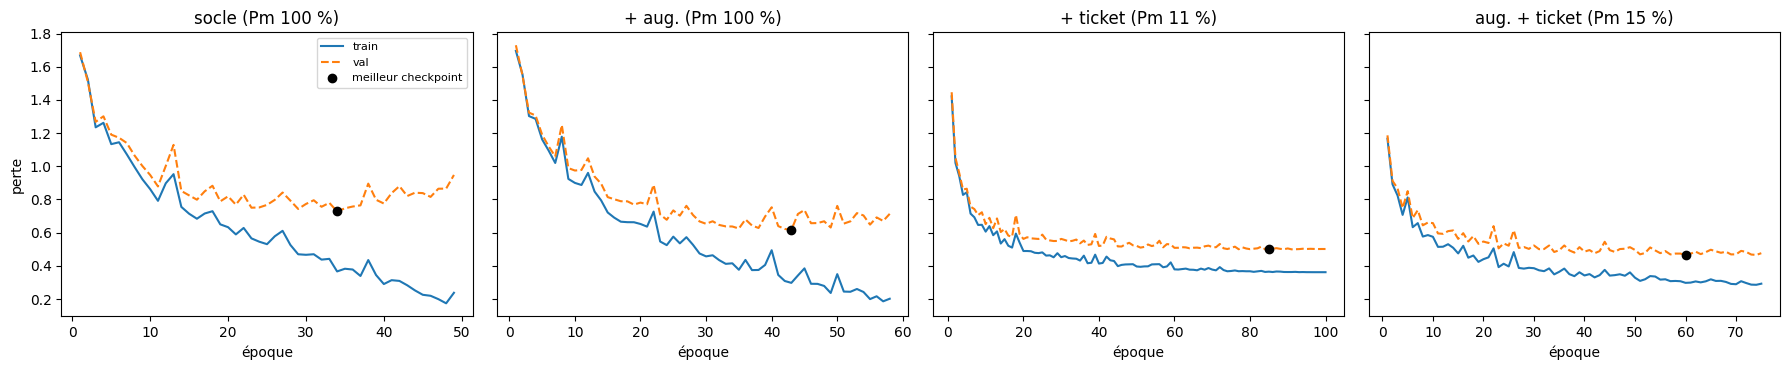

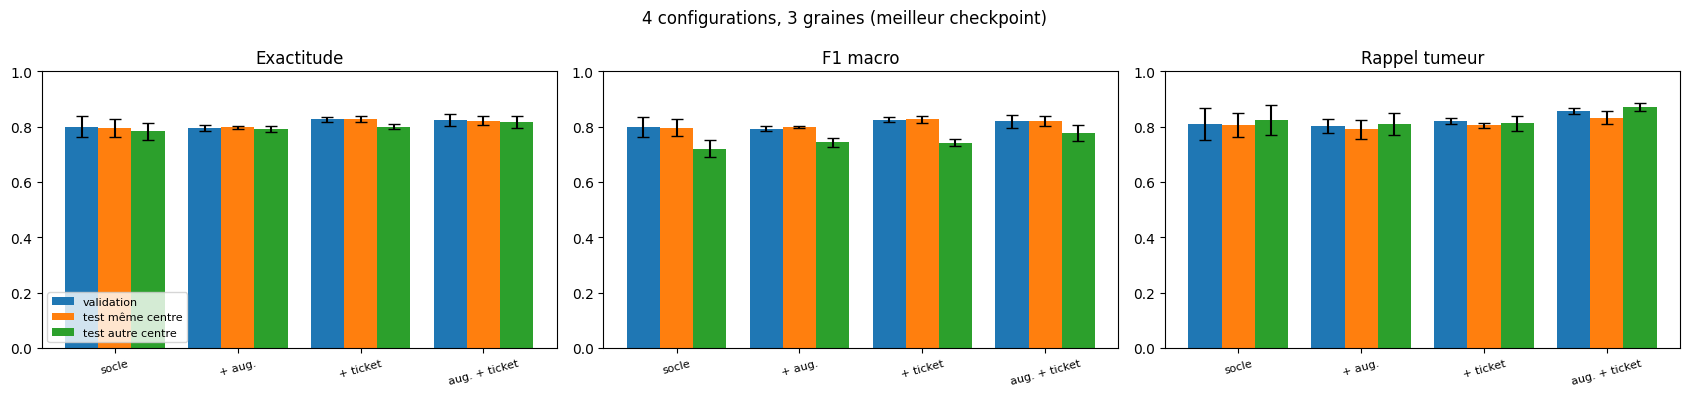

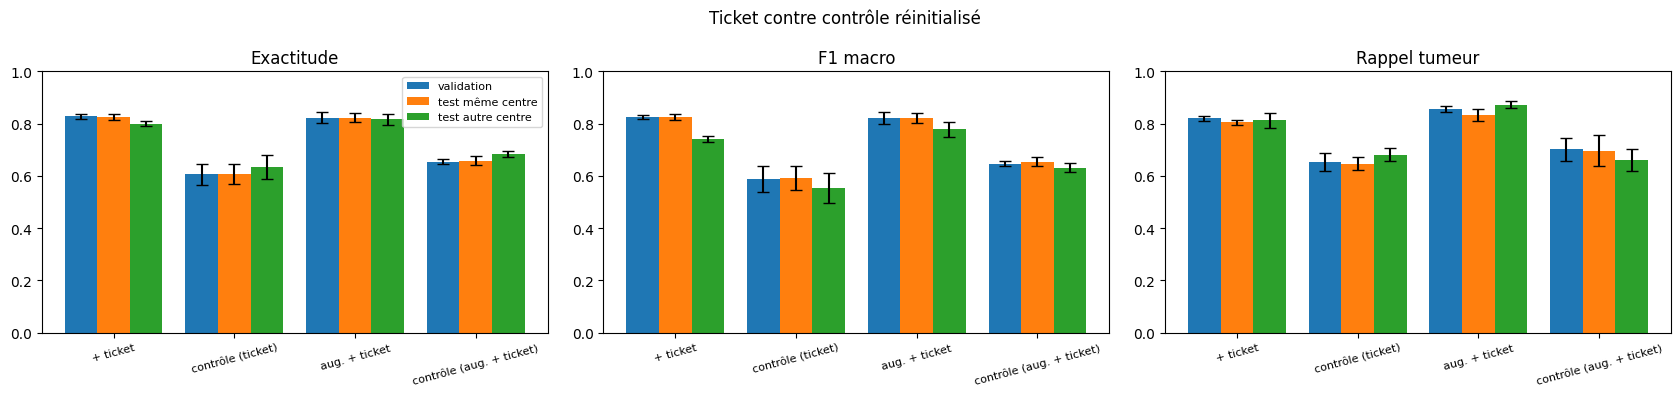

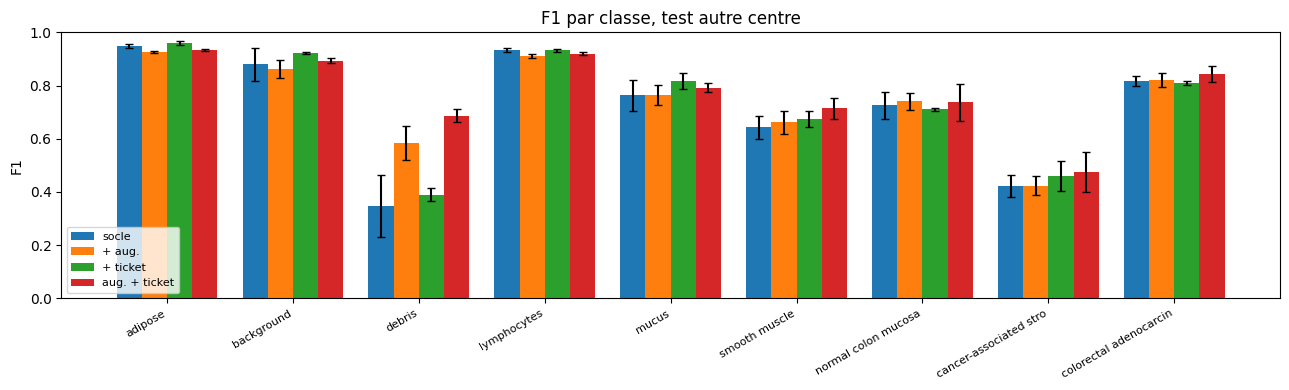

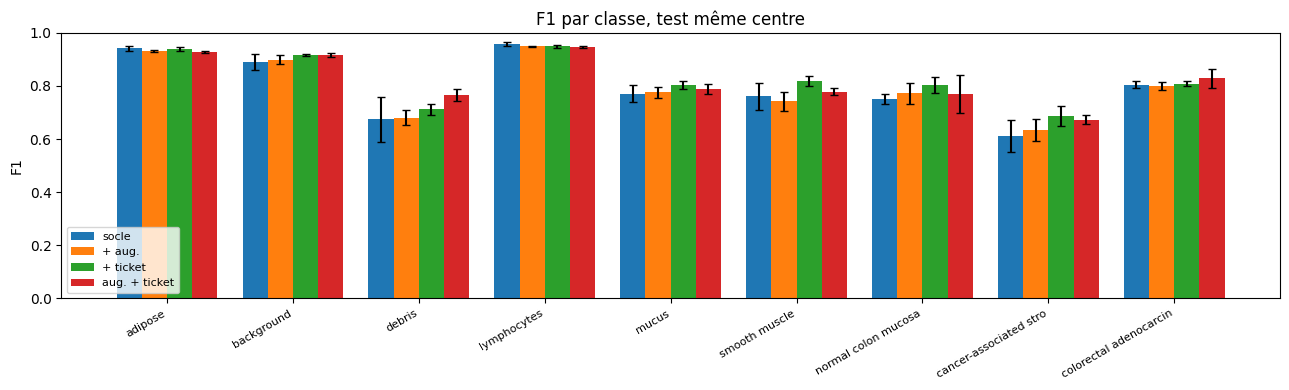

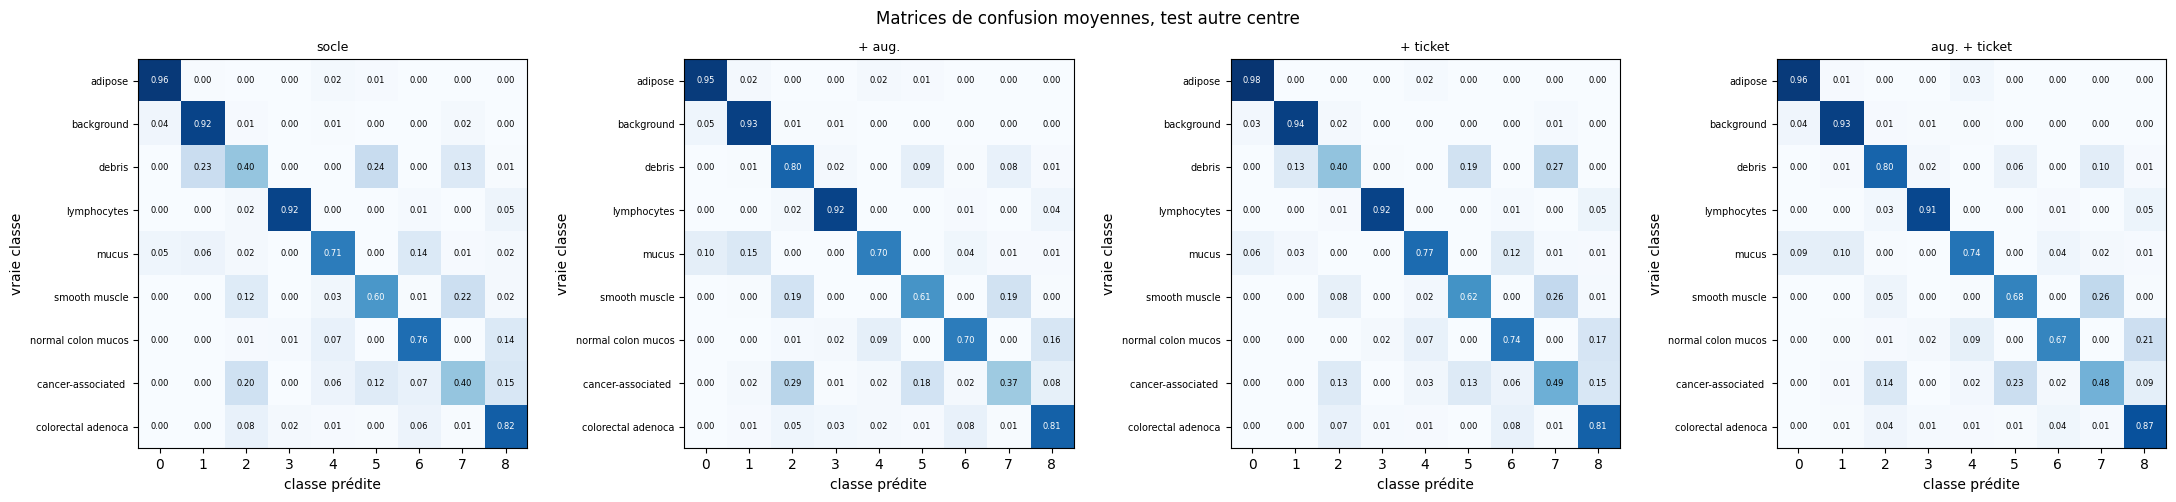

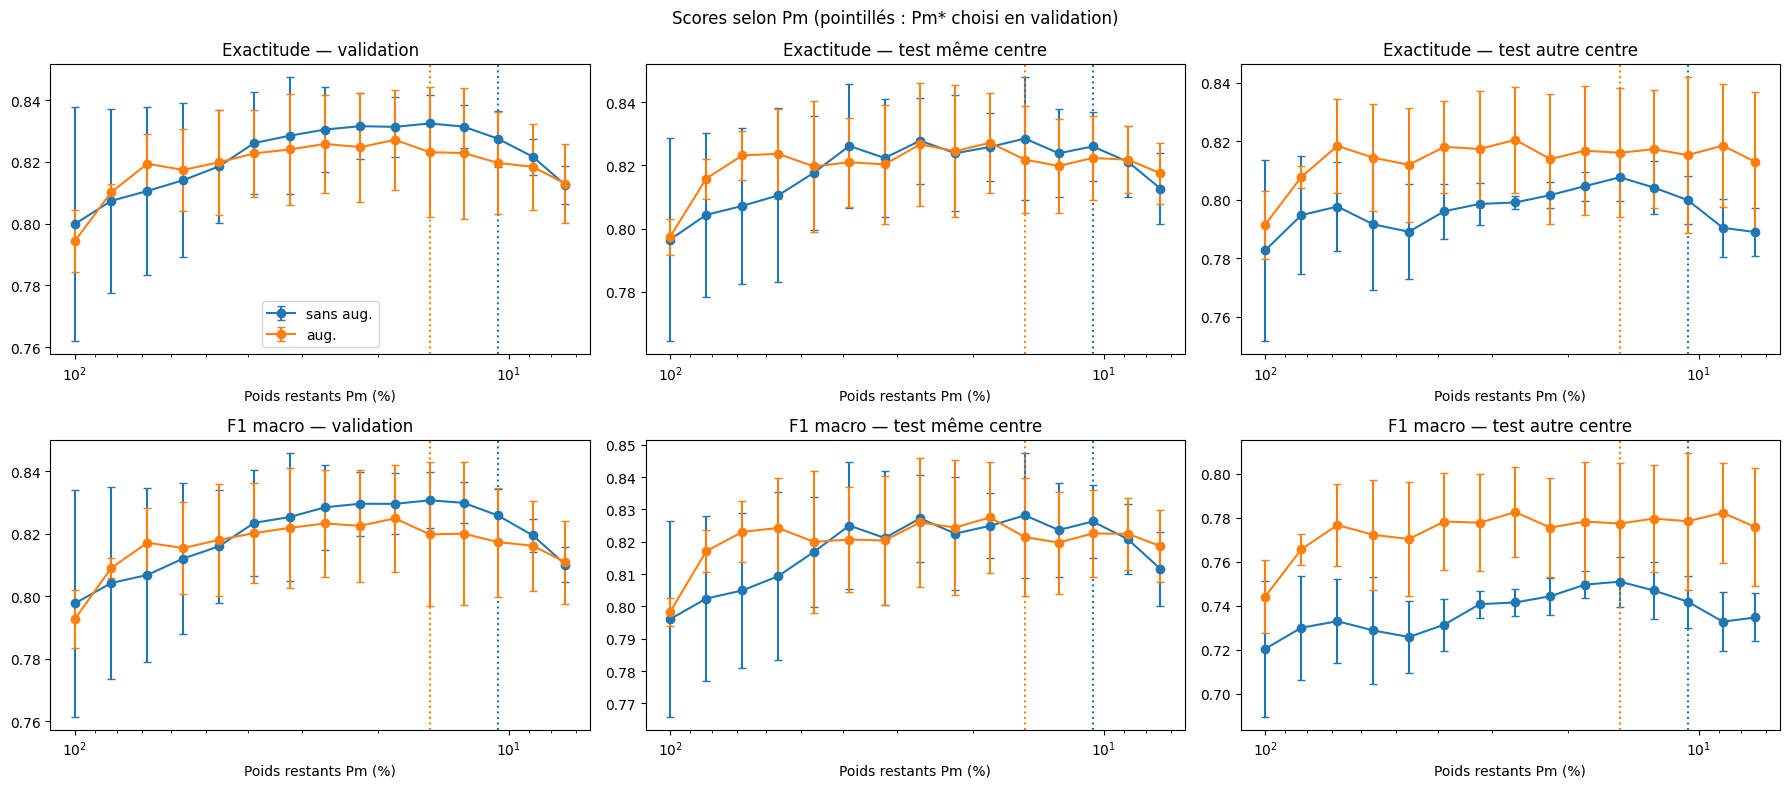

In [56]:
def _mean_sd(values):
    v = np.asarray(values, dtype=float)
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)

def plot_compare(df, models, title):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    for a, (m, mlab) in zip(ax, [("acc", "Exactitude"), ("f1", "F1 macro"), ("rappel_tum", "Rappel tumeur")]):
        x, w = np.arange(len(models)), 0.27
        for i, (key, klab) in enumerate([("val", "validation"), ("same", "test même centre"), ("other", "test autre centre")]):
            ms = [_mean_sd(df.loc[df["modèle"] == mo, f"{m}_{key}"]) for mo in models]
            a.bar(x + (i - 1) * w, [v[0] for v in ms], w, yerr=[v[1] for v in ms], capsize=4, label=klab)
        a.set_xticks(x); a.set_xticklabels(models, fontsize=8, rotation=15); a.set_ylim(0, 1); a.set_title(mlab)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()

def plot_f1_classes(df, models, key="other", title=""):
    x, w = np.arange(9), 0.8 / len(models)
    plt.figure(figsize=(13, 4))
    for i, mo in enumerate(models):
        arr = np.stack(df.loc[df["modèle"] == mo, f"f1_classes_{key}"].values)
        plt.bar(x + (i - (len(models) - 1) / 2) * w, arr.mean(0), w, yerr=arr.std(0, ddof=1), capsize=3, label=mo)
    plt.xticks(x, [n[:22] for n in names], rotation=30, ha="right", fontsize=8)
    plt.ylabel("F1"); plt.ylim(0, 1); plt.title(title); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

def plot_cms(df, models, key="other", title=""):
    fig, ax = plt.subplots(1, len(models), figsize=(5.5 * len(models), 5))
    for a, mo in zip(np.atleast_1d(ax), models):
        cm = np.mean(np.stack(df.loc[df["modèle"] == mo, f"cm_{key}"].values), axis=0)
        a.imshow(cm, cmap="Blues", vmin=0, vmax=1)
        for i in range(9):
            for j in range(9):
                a.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=6,
                       color="white" if cm[i, j] > 0.5 else "black")
        a.set_xticks(range(9)); a.set_yticks(range(9)); a.set_yticklabels([n[:18] for n in names], fontsize=7)
        a.set_xlabel("classe prédite"); a.set_ylabel("vraie classe"); a.set_title(mo, fontsize=9)
    fig.suptitle(title); plt.tight_layout(); plt.show()

# 1. Courbes de perte, graine 0
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for a, (lab, rec, _) in zip(ax, pick(SEED_TUNE)[:4]):
    h = rec["history"]
    a.plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], label="train")
    a.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], "--", label="val")
    if rec["best_epoch"]:
        a.plot(rec["best_epoch"], h["val_loss"][rec["best_epoch"] - 1], "ko", label="meilleur checkpoint")
    a.set_title(f"{lab} (Pm {100 * rec['Pm']:.0f} %)"); a.set_xlabel("époque")
ax[0].set_ylabel("perte"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

# 2 à 4
plot_compare(res_df, MODELS, "4 configurations, 3 graines (meilleur checkpoint)")
plot_compare(res_df, ["+ ticket", "contrôle (ticket)", "aug. + ticket", "contrôle (aug. + ticket)"],
             "Ticket contre contrôle réinitialisé")
plot_f1_classes(res_df, MODELS, "other", "F1 par classe, test autre centre")
plot_f1_classes(res_df, MODELS, "same", "F1 par classe, test même centre")
plot_cms(res_df, MODELS, "other", "Matrices de confusion moyennes, test autre centre")

# 5. Évolution selon Pm (descriptif)
ev = pd.DataFrame([{"données": label, "graine": s, "Pm (%)": round(100 * r["Pm"], 1),
                    **{k: v for k, v in scores(model_from_state(r["state"]), r["train_acc"], label).items()
                       if not k.startswith(("f1_classes", "cm_"))}}
                   for (label, s), t in traj.items() for r in t])
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for row, (m, mlab) in enumerate([("acc", "Exactitude"), ("f1", "F1 macro")]):
    for col, (key, klab) in enumerate([("val", "validation"), ("same", "test même centre"), ("other", "test autre centre")]):
        a = ax[row, col]
        for label in DATASETS:
            g = ev[ev["données"] == label].groupby("Pm (%)")[f"{m}_{key}"]
            pm = np.array(sorted(g.groups, reverse=True))
            a.errorbar(pm, g.mean().reindex(pm), yerr=g.std().reindex(pm).fillna(0), fmt="o-", capsize=3, label=label)
            a.axvline(ev[(ev["données"] == label)]["Pm (%)"].unique()[n_star[label]], ls=":",
                      color=a.lines[-1].get_color())
        a.set_xscale("log"); a.invert_xaxis(); a.set_xlabel("Poids restants Pm (%)"); a.set_title(f"{mlab} — {klab}")
ax[0, 0].legend(); fig.suptitle("Scores selon Pm (pointillés : Pm* choisi en validation)"); plt.tight_layout(); plt.show()